# 20. Séries com variáveis exógenas

**Objetivo e requisitos.** Usar covariáveis na previsão sem vazamento: declarar o que é conhecido antes (`future`) e o que só é observado com a série (`past`), escolher as variáveis automaticamente, deixar a seleção decidir se elas entram e comparar com × sem exógenas por testes estatísticos. Exemplos: vendas com indicador antecedente (`bjsales`), demanda elétrica com temperatura (`elecdaily`) e um estudo em quatro benchmarks. Extras `stats` e `plot`; baixa os dados na primeira execução.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

import autohybts
from autohybts import AutoHybridExperiment
from autohybts.datasets import list_exog_datasets, load_exog_dataset

warnings.filterwarnings("ignore")
print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc3


## 1. Dados e protocolo

Os conjuntos com exógenas vêm do Rdatasets, já com as colunas `future` indicadas. Todos os experimentos usam as mesmas bases (persistência, persistência sazonal, regressão linear sobre lags e ARIMA, que vira ARIMAX com exógenas), o corretor linear, o orçamento `small` e a semente 42.

In [2]:
SETTINGS = {
    "budget": "small",
    "base_models": ["naive", "seasonal_naive", "linear", "arima"],
    "correctors": ["linear"],
    "session_id": 42,
}
list_exog_datasets()

,description,frequency,future,source
name,,,,
seatbelts,"motoristas mortos ou feridos no Reino Unido, 1...",MS,[lei_cinto],datasets/Seatbelts
bjsales,vendas com indicador antecedente (Box–Jenkins)...,D,[],datasets/BJsales
uschange,"variação do consumo nos EUA ~ renda, produção,...",QS,[],fpp2/uschange
insurance,cotações de seguro ~ gasto planejado com publi...,MS,[publicidade_tv],fpp2/insurance
elecdaily,demanda elétrica diária de Victoria (Austrália...,D,[dia_util],fpp2/elecdaily
vic_elec_daily,demanda elétrica diária de Victoria em GWh ~ t...,D,"[feriado, fim_de_semana]",tsibbledata/vic_elec


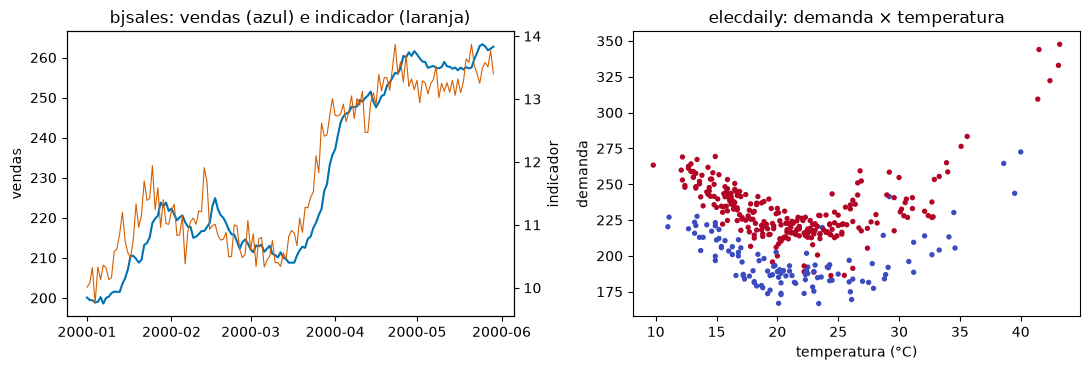

In [3]:
sales, indicator = load_exog_dataset("bjsales")
demand, weather = load_exog_dataset("elecdaily")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(sales.index, sales.to_numpy(), color="#0072B2", label="vendas")
twin = axes[0].twinx()
twin.plot(indicator.index, indicator["indicador"].to_numpy(), color="#D55E00", linewidth=0.8)
axes[0].set(title="bjsales: vendas (azul) e indicador (laranja)", ylabel="vendas")
twin.set_ylabel("indicador")
axes[1].scatter(weather["temperatura"], demand, s=8, c=weather["dia_util"], cmap="coolwarm")
axes[1].set(title="elecdaily: demanda × temperatura", xlabel="temperatura (°C)", ylabel="demanda")
fig.tight_layout()
plt.show()

## 2. Exploração causal

O indicador do `bjsales` antecede as vendas. Com horizonte de 3 passos, ele é `past`: entra defasado em pelo menos 3. `exog_selection="auto"` roda os cinco métodos de seleção e o voto nos dados antes da primeira origem de `V_select`; cada conjunto escolhido vira uma candidata da busca.

In [4]:
plain = AutoHybridExperiment(fh=3, **SETTINGS).fit(sales)
with_exog = AutoHybridExperiment(fh=3, exog_selection="auto", **SETTINGS).fit(sales, indicator)
report = with_exog.exog_report()
report[report.selected].groupby("method").feature.apply(list).to_frame("escolhidas")

,escolhidas
method,
ccf,[indicador_lag3]
granger,[indicador_lag3]
lasso,"[indicador_lag3, indicador_lag4, indicador_lag..."
mutual_info,[indicador_lag3]
stepwise_bic,"[indicador_lag3, indicador_lag4, indicador_lag..."
vote,[indicador_lag3]


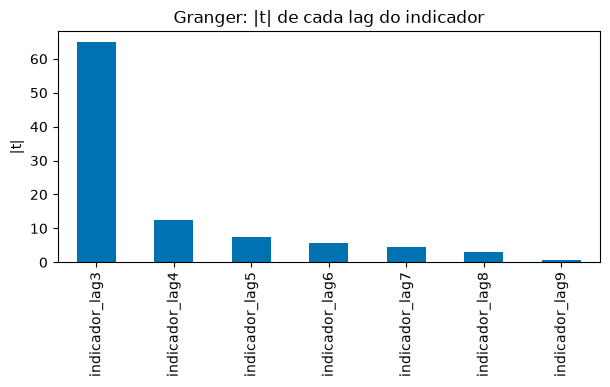

In [5]:
granger = report[report.method == "granger"].set_index("feature")
ax = granger["score"].plot.bar(figsize=(7, 3), color="#0072B2")
ax.set(title="Granger: |t| de cada lag do indicador", ylabel="|t|", xlabel="")
plt.show()

## 3. Controles e modelos propostos

O controle é o mesmo experimento sem `X`. No experimento com `X`, a família `exogenous` (bases com as exógenas e correções residuais sobre as melhores) desafia o campeão univariado depois das estruturas residuais; só entra se passar na regra de aceite.

In [6]:
plain_result = plain.compare_models()
exog_result = with_exog.compare_models()
pd.DataFrame(
    {"campeão": [plain_result.best.label, exog_result.best.label]},
    index=["sem exógenas", "com exógenas"],
)

,campeão
sem exógenas,naive
com exógenas,"linear(lags=7) | exog: indicador_lag3, indicad..."


## 4. Ajuste e avaliação

As decisões da seleção, com ganho mediano e taxa de vitórias; depois, o melhor com e o melhor sem exógenas nas mesmas unidades de `V_select`, com Wilcoxon e Diebold–Mariano.

In [7]:
exog_result.decisions[
    ["family", "challenger_label", "accepted", "median_gain", "win_rate", "reason_codes"]
]

,family,challenger_label,accepted,median_gain,win_rate,reason_codes
0,linear,linear(lags=7),False,-0.305697,0.428571,"(median_gain_below_threshold, win_rate_below_t..."
1,residual,"naive + linear [w=7, alpha=0.5, historical_oof...",False,0.079145,0.571429,"(win_rate_below_threshold,)"
2,exogenous,"linear(lags=7) | exog: indicador_lag3, indicad...",True,0.692053,0.857143,"(accepted,)"


In [8]:
comparison = with_exog.compare_exog()
display(comparison.summary.round(3))
comparison.tests().round(4)

,mean,std,median,n_valid,n_units,mean_rank
model,,,,,,
linear+exog,0.040,0.022,0.036,7,7,1.0
naive-linear,0.173,0.138,0.092,7,7,2.0


,model,reference,n_units,mean_difference,median_difference,wins,wilcoxon_p,dm_statistic,dm_p,wilcoxon_p_holm,dm_p_holm
0,linear+exog,naive-linear,7,0.1333,0.0486,7,0.0156,2.6258,0.0393,0.0156,0.0393


## 5. Resultados e gráficos

Cada campeão é reajustado no histórico anterior ao teste e lido uma vez no teste selado.

In [9]:
final_plain = plain.finalize_model(plain_result.best)
final_exog = with_exog.finalize_model(exog_result.best)
test_plain = plain.evaluate_external(final_plain)
test_exog = with_exog.evaluate_external(final_exog)
pd.concat([test_plain.metrics, test_exog.metrics]).round(3)

,MASE,MAE,RMSE,sMAPE
model,,,,
naive,0.110,0.567,0.676,0.002
"linear(lags=7) | exog: indicador_lag3, indicador_lag4, indicador_lag5, indicador_lag6, indicador_lag7, indicador_lag8",0.029,0.151,0.170,0.001


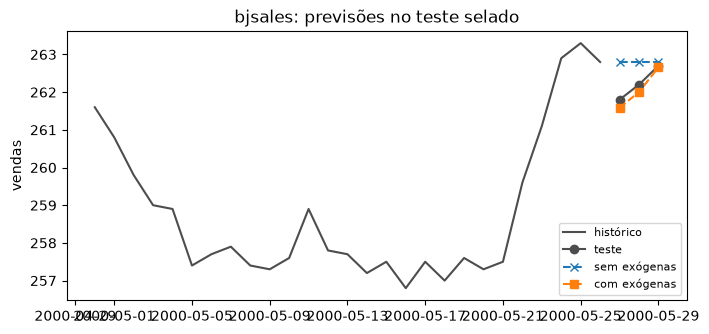

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.5))
history = sales.iloc[-30:-3]
ax.plot(history.index, history.to_numpy(), color="0.3", label="histórico")
ax.plot(
    test_exog.predictions.index, test_exog.predictions["y_true"], "o-", color="0.3", label="teste"
)
ax.plot(test_plain.predictions.index, test_plain.predictions["y_pred"], "x--", label="sem exógenas")
ax.plot(test_exog.predictions.index, test_exog.predictions["y_pred"], "s--", label="com exógenas")
ax.set(title="bjsales: previsões no teste selado", ylabel="vendas")
ax.legend(fontsize=8)
plt.show()

### Oráculo: a temperatura do próprio dia

No `elecdaily`, o dia útil é calendário (`future`). A temperatura medida é `past`: com horizonte de 7 dias, entra defasada 7 dias. Declará-la `future` usa a temperatura do próprio dia, que só seria conhecida depois: é o erro de quem tivesse uma previsão do tempo perfeita, o teto do que ela pode trazer.

In [11]:
def study(y, X, fh, future=(), selection=None):
    """Experiments without and with X; decision, tests and sealed-test MASE."""
    without = AutoHybridExperiment(fh=fh, **SETTINGS).fit(y)
    best_without = without.compare_models().best
    mase_without = (
        without.evaluate_external(without.finalize_model(best_without)).metrics["MASE"].iloc[0]
    )
    exp = AutoHybridExperiment(
        fh=fh, exog_future=list(future), exog_selection=selection, **SETTINGS
    ).fit(y, X)
    result = exp.compare_models()
    decision = result.decisions.set_index("family").loc["exogenous"]
    tests = exp.compare_exog().tests().iloc[0]
    mase_with = exp.evaluate_external(exp.finalize_model(result.best)).metrics["MASE"].iloc[0]
    return {
        "aceito": bool(decision.accepted),
        "ganho_mediano": float(decision.median_gain),
        "vitorias": float(decision.win_rate),
        "wilcoxon_p": float(tests.wilcoxon_p),
        "dm_p": float(tests.dm_p),
        "mase_teste_sem": float(mase_without),
        "mase_teste_com": float(mase_with),
    }


oracle = pd.DataFrame(
    {
        "temperatura past": study(demand, weather, 7, future=["dia_util"]),
        "temperatura future (oráculo)": study(
            demand, weather, 7, future=["dia_util", "temperatura", "temperatura2"]
        ),
    }
).T.infer_objects()
oracle.round(3)

,aceito,ganho_mediano,vitorias,wilcoxon_p,dm_p,mase_teste_sem,mase_teste_com
temperatura past,False,-0.040,0.429,0.578,0.388,1.954,1.954
temperatura future (oráculo),True,0.284,0.857,0.031,0.021,1.954,0.689


## 6. Diagnóstico e limites

O mesmo estudo em mais dois benchmarks, com seleção automática: `seatbelts` (mensal, horizonte 12, lei do cinto como `future`) e `uschange` (trimestral, horizonte 8). Covariáveis `past` precisam estar defasadas pelo horizonte inteiro; em horizontes longos elas raramente informam, e a regra de aceite as recusa. O índice diário do `bjsales` é sintético.

In [12]:
bjsales_row = study(sales, indicator, 3, selection="auto")
y_seat, X_seat = load_exog_dataset("seatbelts")
y_us, X_us = load_exog_dataset("uschange")
benchmarks = pd.DataFrame(
    {
        "bjsales (fh=3)": bjsales_row,
        "elecdaily (fh=7)": oracle.iloc[0].to_dict(),
        "seatbelts (fh=12)": study(y_seat, X_seat, 12, future=["lei_cinto"], selection="auto"),
        "uschange (fh=8)": study(y_us, X_us, 8, selection="auto"),
    }
).T.infer_objects()
benchmarks.round(3)

,aceito,ganho_mediano,vitorias,wilcoxon_p,dm_p,mase_teste_sem,mase_teste_com
bjsales (fh=3),True,0.692,0.857,0.016,0.039,0.110,0.029
elecdaily (fh=7),False,-0.040,0.429,0.578,0.388,1.954,1.954
seatbelts (fh=12),False,-0.612,0.167,0.219,0.141,0.714,0.714
uschange (fh=8),False,-0.149,0.286,0.156,0.198,0.322,0.322


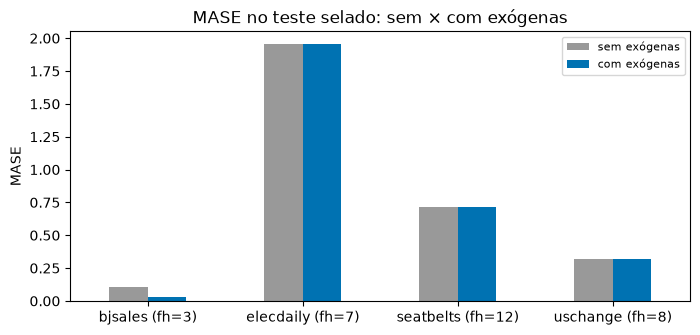

In [13]:
ax = benchmarks[["mase_teste_sem", "mase_teste_com"]].plot.bar(
    figsize=(8, 3.5), rot=0, color=["0.6", "#0072B2"]
)
ax.set(title="MASE no teste selado: sem × com exógenas", ylabel="MASE")
ax.legend(["sem exógenas", "com exógenas"], fontsize=8)
plt.show()

## 7. Leitura

- **Indicador antecedente (`bjsales`, horizonte 3).** Os seis métodos escolheram o indicador defasado 3 passos; `lasso` e `stepwise_bic` levaram também lags vizinhos. A família `exogenous` foi aceita com ganho mediano de 69 % e 6 vitórias em 7 origens. Wilcoxon deu p = 0,016, o menor possível com 7 unidades, e Diebold–Mariano p = 0,039. No teste selado, o MASE caiu de 0,110 (persistência) para 0,029.
- **Temperatura `past` (`elecdaily`, horizonte 7).** Defasada 7 dias, a temperatura não ajudou: ganho de −4 %, e o campeão continuou univariado.
- **Oráculo.** Declarada `future`, a temperatura do próprio dia (e o seu quadrado, porque a demanda sobe no frio e no calor) foi aceita, com ganho de 28 %. O MASE no teste caiu de 1,95 para 0,69. Esse é o teto: em produção, a coluna viria de uma previsão do tempo, com erro. A distância entre 1,95 e 0,69 é o quanto uma boa previsão de temperatura vale para esta série.
- **Horizontes longos.** Em `seatbelts` (horizonte 12) e `uschange` (horizonte 8), as covariáveis `past` defasadas pelo horizonte inteiro pioraram a validação (ganhos de −61 % e −15 %). A regra de aceite as recusou, e o modelo final é o mesmo do experimento sem `X`.
- **O que fica.** As exógenas ajudam quando antecedem a série pelo horizonte ou são de fato conhecidas antes. Quando não ajudam, a seleção as recusa e registra o motivo: o custo de oferecê-las é só o tempo da busca.